In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

df = pd.read_csv("../results/part1_known_warps.csv")
wide = df.pivot_table(index=["case", "group"], columns="method",
                      values="normal_p95_mm").reset_index()
dis = df.groupby("case").ants_vs_ugi_disagreement_mm.first()
wide["disagreement_mm"] = wide.case.map(dis)
wide["any_failed"] = (wide[["ANTs SyN", "uniGradICON"]] > 2).any(axis=1)
print(wide.any_failed.value_counts())
wide.head()

any_failed
True     174
False     16
Name: count, dtype: int64


method,case,group,ANTs SyN,affine,uniGradICON,disagreement_mm,any_failed
0,BraTS-GLI-00005-000,GLI,1.465197,2.047996,4.076084,1.352466,True
1,BraTS-GLI-00008-001,GLI,1.554998,1.942215,4.892808,1.668281,True
2,BraTS-GLI-00011-000,GLI,1.217252,1.854285,3.160640,1.117581,True
3,BraTS-GLI-00020-000,GLI,0.993606,1.903895,4.203958,1.340255,True
4,BraTS-GLI-00024-001,GLI,1.010238,1.750834,5.914093,2.108169,True


In [2]:
for m in ["ANTs SyN", "uniGradICON"]:
    rho, p = spearmanr(wide.disagreement_mm, wide[m])
    print(f"{m}: Spearman rho = {rho:.2f} (p = {p:.3g})")

if wide.any_failed.nunique() == 2:
    auc = roc_auc_score(wide.any_failed, wide.disagreement_mm)
    r = np.random.default_rng(0); boots = []
    for _ in range(2000):
        s = wide.sample(len(wide), replace=True, random_state=r.integers(1e9))
        if s.any_failed.nunique() == 2:
            boots.append(roc_auc_score(s.any_failed, s.disagreement_mm))
    print(f"AUC for flagging a failed registration: {auc:.2f} "
          f"(95% CI {np.percentile(boots, 2.5):.2f} to {np.percentile(boots, 97.5):.2f})")
else:
    print("Only one class: no failures (or all failures) at 2 mm, so AUC is undefined. Tell me, we'll discuss.")

ANTs SyN: Spearman rho = 0.37 (p = 1.31e-07)
uniGradICON: Spearman rho = 0.98 (p = 1.91e-127)
AUC for flagging a failed registration: 0.98 (95% CI 0.96 to 1.00)


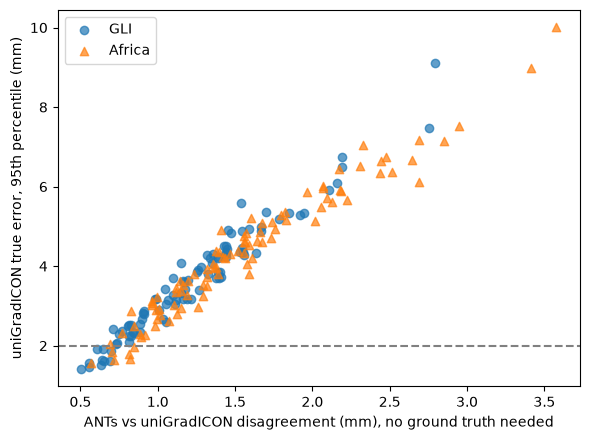

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for grp, mk in [("GLI", "o"), ("Africa", "^")]:
    g = wide[wide.group == grp]
    ax.scatter(g.disagreement_mm, g["uniGradICON"], marker=mk, alpha=0.7, label=grp)
ax.axhline(2, ls="--", c="gray")
ax.set_xlabel("ANTs vs uniGradICON disagreement (mm), no ground truth needed")
ax.set_ylabel("uniGradICON true error, 95th percentile (mm)")
ax.legend(); plt.tight_layout()
plt.savefig("../figures/disagreement_vs_error.png", dpi=150); plt.show()